<a href="https://colab.research.google.com/github/Karan0052/AF05150020_LibraryManagementSystem/blob/main/sepsis_project_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Early Sepsis Prediction from EHR — end-to-end project (one file)



In [1]:
N_PER_SET = 4000
EPOCHS    = 15
SEEDS     = [0, 1, 2]

In [2]:
import torch
print("torch", torch.__version__, "| GPU:", torch.cuda.is_available())
if not torch.cuda.is_available():
    print("WARNING: no GPU. Runtime > Change runtime type > T4 GPU, otherwise this will be very slow.")
!mkdir -p src results figures data

torch 2.11.0+cu130 | GPU: True


In [3]:
%%writefile src/__init__.py
# package marker

Writing src/__init__.py


In [4]:
%%writefile src/features.py
"""Column definitions and feature-layout constants shared by every module."""

# 8 vitals + 26 labs (time-varying, frequently missing)
DYNAMIC = [
    "HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2",
    "BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST", "BUN",
    "Alkalinephos", "Calcium", "Chloride", "Creatinine", "Bilirubin_direct",
    "Glucose", "Lactate", "Magnesium", "Phosphate", "Potassium",
    "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT", "WBC",
    "Fibrinogen", "Platelets",
]
# demographics / administrative, always (almost) observed
STATIC = ["Age", "Gender", "Unit1", "Unit2", "HospAdmTime", "ICULOS"]
LABEL = "SepsisLabel"
ALL_COLS = DYNAMIC + STATIC + [LABEL]

NDYN = len(DYNAMIC)      # 34
NSTAT = len(STATIC)      # 6

# Per-hour feature vector layout (what the networks see):
#   [ x (ffilled+normalised) | m (observed this hour) | dt (hours since last obs / 48) | static ]
IDX_X = slice(0, NDYN)
IDX_M = slice(NDYN, 2 * NDYN)
IDX_DT = slice(2 * NDYN, 3 * NDYN)
IDX_S = slice(3 * NDYN, 3 * NDYN + NSTAT)
N_FEAT = 3 * NDYN + NSTAT   # 108
IN_DIM = N_FEAT + 1         # +1: "is a real (non-padding) step" flag, appended last by Windows.gather

DT_CAP = 48                 # hours; cap for "time since last measurement"
CHALLENGE_LEAD = 6          # PhysioNet labels start 6 h BEFORE clinical onset (Sepsis-3 t_sepsis)
VAR_NAMES = DYNAMIC + STATIC

Writing src/features.py


In [5]:
%%writefile src/data.py
"""Loading, labelling, splitting and featurising the PhysioNet/CinC 2019 sepsis data."""
import glob
import hashlib
import os
import pickle
import warnings
from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from .features import (ALL_COLS, CHALLENGE_LEAD, DT_CAP, DYNAMIC, LABEL, STATIC)


# ----------------------------------------------------------------------------- loading
def find_set_dirs(data_dir):
    """Locate training_setA / training_setB anywhere below data_dir."""
    dirs = {}
    for name in ("training_setA", "training_setB"):
        hits = [h for h in glob.glob(os.path.join(data_dir, "**", name), recursive=True) if os.path.isdir(h)]
        if hits:
            dirs[name[-1]] = hits[0]
    if not dirs:
        raise FileNotFoundError(
            f"No training_setA / training_setB folders under '{data_dir}'. "
            "Run scripts/download_data.sh or `python -m src.synthetic` first.")
    return dirs


def load_raw(data_dir, max_per_set=None, cache_dir="data/processed"):
    """Read every .psv file. Returns list of dicts: id, src, dyn (T,34), stat (T,6), label (T,)."""
    key = hashlib.md5(os.path.abspath(data_dir).encode()).hexdigest()[:8]
    cache = os.path.join(cache_dir, f"raw_{key}_{max_per_set or 'all'}.pkl")
    if os.path.exists(cache):
        with open(cache, "rb") as f:
            return pickle.load(f)
    stays = []
    for src, d in find_set_dirs(data_dir).items():
        files = sorted(glob.glob(os.path.join(d, "*.psv")))
        if max_per_set:
            files = files[:max_per_set]
        for f in files:
            df = pd.read_csv(f, sep="|")[ALL_COLS]
            stays.append({
                "id": os.path.basename(f)[:-4],
                "src": src,
                "dyn": df[DYNAMIC].to_numpy(np.float32),
                "stat": df[STATIC].to_numpy(np.float32),
                "label": df[LABEL].to_numpy(np.int8),
            })
    os.makedirs(cache_dir, exist_ok=True)
    with open(cache, "wb") as f:
        pickle.dump(stays, f)
    return stays


# ----------------------------------------------------------------------------- labels
def label_info(label_raw, horizon):
    """Convert the challenge labels into 'sepsis within `horizon` hours' labels.

    The challenge's SepsisLabel switches to 1 at (clinical onset - 6h). We recover the
    clinical onset as first_positive + 6 and re-derive labels for any horizon:
        y[t] = 1  iff  onset - horizon <= t < onset
    Hours at/after onset are 'invalid' for training and classification metrics (the diagnosis
    is already made) but are still scored by the PhysioNet utility function.
    Returns y (T,), valid (T,) bool, onset (int, -1 if never septic).
    """
    T = len(label_raw)
    y = np.zeros(T, np.int8)
    if label_raw.any():
        onset = int(np.argmax(label_raw)) + CHALLENGE_LEAD
        y[max(0, onset - horizon):min(T, onset)] = 1
        n_valid = min(T, onset)
    else:
        onset, n_valid = -1, T
    return y, np.arange(T) < n_valid, onset


# ----------------------------------------------------------------------------- splits
def make_splits(stays, mode="random", seed=0, val_frac=0.15, test_frac=0.15):
    """Patient-level, stratified-by-sepsis splits. Never splits a stay across sets.

    mode='random'  : 70/15/15 over all stays (hospital systems A and B pooled)
    mode='hospital': train/val from hospital A, test = ALL of hospital B  (external validation)
    """
    idx = np.arange(len(stays))
    septic = np.array([s["label"].any() for s in stays]).astype(int)
    if mode == "random":
        trval, te = train_test_split(idx, test_size=test_frac, stratify=septic, random_state=seed)
        tr, va = train_test_split(trval, test_size=val_frac / (1 - test_frac),
                                  stratify=septic[trval], random_state=seed)
    elif mode == "hospital":
        src = np.array([s["src"] for s in stays])
        A, B = idx[src == "A"], idx[src == "B"]
        if len(A) == 0 or len(B) == 0:
            raise ValueError("split_mode='hospital' needs both training_setA and training_setB")
        tr, va = train_test_split(A, test_size=val_frac, stratify=septic[A], random_state=seed)
        te = B
    else:
        raise ValueError(mode)
    return {"train": np.sort(tr), "val": np.sort(va), "test": np.sort(te)}


# ----------------------------------------------------------------------------- features
def fit_normalizer(train_stays):
    """Mean/std from TRAINING stays only (observed values only for the dynamic columns)."""
    dyn = np.concatenate([s["dyn"] for s in train_stays])
    stat = np.concatenate([s["stat"] for s in train_stays])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        mean_d, std_d = np.nanmean(dyn, 0), np.nanstd(dyn, 0)
        mean_s, std_s = np.nanmean(stat, 0), np.nanstd(stat, 0)
    out = {}
    for k, (m, s) in {"d": (mean_d, std_d), "s": (mean_s, std_s)}.items():
        m = np.nan_to_num(m, nan=0.0)
        s = np.nan_to_num(s, nan=1.0)
        out["mean_" + k] = m.astype(np.float32)
        out["std_" + k] = np.where(s < 1e-6, 1.0, s).astype(np.float32)
    return out


def featurize(stay, norm):
    """-> (T, 108) float32: [x | m | dt | static]. See features.py for the layout."""
    dyn = stay["dyn"]
    T = len(dyn)
    m = ~np.isnan(dyn)
    ff = pd.DataFrame(dyn).ffill().to_numpy(np.float32)            # last observation carried forward
    t = np.arange(T)[:, None]
    last_obs = np.maximum.accumulate(np.where(m, t, -1), axis=0)
    dt = np.where(last_obs >= 0, t - last_obs, DT_CAP)
    dt = (np.minimum(dt, DT_CAP) / DT_CAP).astype(np.float32)       # hours since last measurement, in [0,1]
    x = np.clip((ff - norm["mean_d"]) / norm["std_d"], -5, 5)
    x = np.nan_to_num(x, nan=0.0)                                   # never observed -> training mean
    st = np.clip((stay["stat"] - norm["mean_s"]) / norm["std_s"], -5, 5)
    st = np.nan_to_num(st, nan=0.0)
    return np.concatenate([x, m.astype(np.float32), dt, st], axis=1).astype(np.float32)


@dataclass
class Cohort:
    stays: list      # each dict has id, src, dyn, stat, label, feats
    splits: dict     # name -> np.ndarray of stay indices
    norm: dict


def build_cohort(data_dir, split_mode="random", split_seed=0, max_per_set=None, cache_dir="data/processed"):
    stays = load_raw(data_dir, max_per_set, cache_dir)
    splits = make_splits(stays, split_mode, split_seed)
    norm = fit_normalizer([stays[i] for i in splits["train"]])
    for s in stays:
        s["feats"] = featurize(s, norm)
    return Cohort(stays, splits, norm)

Writing src/data.py


In [6]:
%%writefile src/windows.py
"""Numpy-only helper that turns stays into (stay, hour) rows and gathers lookback windows.

Every hour of every stay is one row; the model input for row (s, t) is the `window` hours
ending at t (left-padded with zeros, plus a 'real step' flag as the last channel).
"""
import numpy as np

from .data import label_info
from .features import IDX_DT, IDX_M


class Windows:
    def __init__(self, stays, idxs, horizon, window, drop_missing_feats=False):
        self.stays = [stays[i] for i in idxs]
        self.stay_idx = np.asarray(idxs)
        self.window = window
        infos = [label_info(s["label"], horizon) for s in self.stays]
        self.lens = np.array([len(s["feats"]) for s in self.stays])
        self.offsets = np.concatenate([[0], np.cumsum(self.lens)[:-1]])
        self.F = np.concatenate([s["feats"] for s in self.stays]).astype(np.float32)
        if drop_missing_feats:                       # ablation: no missingness indicators / time-since
            self.F[:, IDX_M] = 0.0
            self.F[:, IDX_DT] = 0.0
        self.y = np.concatenate([i[0] for i in infos])
        self.valid = np.concatenate([i[1] for i in infos])
        self.onset = np.array([i[2] for i in infos])
        self.n_valid = np.array([int(i[1].sum()) for i in infos])
        self.raw_label = np.concatenate([s["label"] for s in self.stays])
        self.row_stay = np.repeat(np.arange(len(self.stays)), self.lens)
        self.row_off = self.offsets[self.row_stay]
        self.row_t = np.arange(len(self.F)) - self.row_off

    @property
    def N(self):
        return len(self.F)

    def gather(self, rows):
        """rows: int array (B,) -> float32 array (B, window, N_FEAT+1)."""
        t = self.row_t[rows][:, None] + np.arange(-self.window + 1, 1)[None, :]
        ok = t >= 0
        idx = self.row_off[rows][:, None] + np.maximum(t, 0)
        X = self.F[idx] * ok[..., None]
        return np.concatenate([X, ok[..., None].astype(np.float32)], axis=-1)

    def train_rows(self, neg_ratio, rng):
        """All valid positives + `neg_ratio` x as many random valid negatives (re-drawn each epoch)."""
        pos = np.flatnonzero(self.valid & (self.y == 1))
        neg = np.flatnonzero(self.valid & (self.y == 0))
        if neg_ratio is not None and len(neg) > neg_ratio * len(pos):
            neg = rng.choice(neg, size=int(neg_ratio * len(pos)), replace=False)
        rows = np.concatenate([pos, neg])
        rng.shuffle(rows)
        return rows

    def split_by_stay(self, arr):
        return np.split(arr, np.cumsum(self.lens)[:-1])

Writing src/windows.py


In [7]:
%%writefile src/metrics.py
"""Metrics: hour-level discrimination/calibration, PhysioNet-2019 utility, patient-level alerting."""
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

# ---- PhysioNet/CinC 2019 utility parameters (official values) ----
DT_EARLY, DT_OPT, DT_LATE = -12, -6, 3
MAX_U_TP, MIN_U_FN, U_FP, U_TN = 1.0, -2.0, -0.05, 0.0


# ----------------------------------------------------------------------------- hour level
def expected_calibration_error(y, p, bins=10):
    """Equal-mass-bin ECE (equal-width bins are useless when prevalence is ~1%)."""
    order = np.argsort(p)
    ece = 0.0
    for chunk in np.array_split(order, bins):
        if len(chunk):
            ece += len(chunk) / len(p) * abs(p[chunk].mean() - y[chunk].mean())
    return float(ece)


def hour_metrics(y, p, is_probability=True):
    out = {"n_hours": int(len(y)), "prevalence": float(y.mean())}
    if y.min() == y.max():
        return out
    out["auroc"] = float(roc_auc_score(y, p))
    out["auprc"] = float(average_precision_score(y, p))
    fpr, tpr, _ = roc_curve(y, p)
    for spec in (0.90, 0.95, 0.99):
        out[f"sens@spec{int(spec * 100)}"] = float(tpr[fpr <= 1 - spec].max())
    if is_probability:
        out["brier"] = float(np.mean((p - y) ** 2))
        out["ece"] = expected_calibration_error(y, p)
    return out


def _logit(p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))


def fit_platt(p, y, max_n=400_000, seed=0):
    """Logistic recalibration on validation data (training uses negative subsampling, which inflates p)."""
    z = _logit(p)[:, None]
    if len(z) > max_n:
        sel = np.random.default_rng(seed).choice(len(z), max_n, replace=False)
        z, y = z[sel], y[sel]
    return LogisticRegression(C=1e6, max_iter=300).fit(z, y)


def apply_platt(cal, p):
    return cal.predict_proba(_logit(p)[:, None])[:, 1]


# ----------------------------------------------------------------------------- utility
def utility_arrays(label_raw):
    """Per-hour utility if we alert (u_pos) / stay silent (u_neg), plus the 'perfect' alert pattern.

    Vectorised re-implementation of the official PhysioNet 2019 compute_prediction_utility().
    Verify against the official evaluate_sepsis_score.py before quoting numbers in a paper.
    """
    T = len(label_raw)
    d_idx = np.arange(T)
    u_pos, u_neg, best = np.full(T, U_FP), np.zeros(T), np.zeros(T, bool)
    if label_raw.any():
        t_sepsis = int(np.argmax(label_raw)) - DT_OPT            # = first positive label + 6
        m1 = MAX_U_TP / (DT_OPT - DT_EARLY); b1 = -m1 * DT_EARLY
        m2 = -MAX_U_TP / (DT_LATE - DT_OPT); b2 = -m2 * DT_LATE
        m3 = MIN_U_FN / (DT_LATE - DT_OPT);  b3 = -m3 * DT_OPT
        d = d_idx - t_sepsis
        active = d <= DT_LATE
        tp = np.where(d <= DT_OPT, np.maximum(m1 * d + b1, U_FP), m2 * d + b2)
        fn = np.where(d >= DT_OPT, m3 * d + b3, 0.0)
        u_pos = np.where(active, tp, 0.0)
        u_neg = np.where(active, fn, 0.0)
        best[max(0, t_sepsis + DT_EARLY):min(t_sepsis + DT_LATE + 1, T)] = True
    return u_pos, u_neg, best


class UtilityScorer:
    """Normalised utility: 1 = perfect timing, 0 = never alerting, <0 = worse than silence."""

    def __init__(self, labels_per_stay):
        arrs = [utility_arrays(l) for l in labels_per_stay]
        self.u_pos = np.concatenate([a[0] for a in arrs])
        self.u_neg = np.concatenate([a[1] for a in arrs])
        best = np.concatenate([a[2] for a in arrs])
        self.u_no = float(self.u_neg.sum())
        self.u_opt = float(np.where(best, self.u_pos, self.u_neg).sum())

    def score(self, alert):
        u = float(np.where(alert, self.u_pos, self.u_neg).sum())
        return (u - self.u_no) / (self.u_opt - self.u_no)

    def best_threshold(self, p, n_grid=200):
        qs = np.unique(np.quantile(p, np.linspace(0.5, 0.9998, n_grid)))
        scores = [self.score(p >= t) for t in qs]
        k = int(np.argmax(scores))
        return float(qs[k]), float(scores[k])


# ----------------------------------------------------------------------------- patient level
def patient_metrics(p_by_stay, n_valid, onset, thr):
    """Alert rules: fire the first time p >= thr (before clinical onset)."""
    det, lead, n_sep, n_non, fa_stays, alert_h, hours_non = 0, [], 0, 0, 0, 0, 0
    for p, nv, on in zip(p_by_stay, n_valid, onset):
        alerts = np.flatnonzero(p[:nv] >= thr)
        if on >= 0:
            n_sep += 1
            if len(alerts):
                det += 1
                lead.append(on - alerts[0])
        else:
            n_non += 1
            fa_stays += int(len(alerts) > 0)
            alert_h += len(alerts)
            hours_non += nv
    return {
        "n_septic": n_sep, "n_nonseptic": n_non,
        "sensitivity_patient": det / max(n_sep, 1),
        "median_lead_time_h": float(np.median(lead)) if lead else None,
        "iqr_lead_time_h": [float(np.percentile(lead, 25)), float(np.percentile(lead, 75))] if lead else None,
        "nonseptic_stays_with_alert": fa_stays / max(n_non, 1),
        "false_alert_hours_per_100_patient_days": 2400.0 * alert_h / max(hours_non, 1),
    }

Writing src/metrics.py


In [8]:
%%writefile src/evaluate.py
"""One evaluation routine shared by every model (deep nets, GBDT, LR, clinical scores)."""
import numpy as np

from .metrics import (UtilityScorer, apply_platt, expected_calibration_error, fit_platt,
                      hour_metrics, patient_metrics)


def evaluate_predictions(win_test, p_test, win_val=None, p_val=None, thr=None,
                         recalibrate=True, is_probability=True):
    """Evaluate per-hour scores on the test windows.

    p_* : array (N_rows,) with one score for EVERY hour of every stay (post-onset hours included;
          the PhysioNet utility needs them, classification metrics ignore them).
    Threshold: if `thr` is None it is chosen on validation data by maximising normalised utility
    (never on test). Probabilities are Platt-recalibrated on validation if requested.
    Returns (metrics dict, calibrated p_test, calibrated p_val).
    """
    p_test_c, p_val_c, cal = p_test, p_val, None
    if recalibrate and p_val is not None:
        mv = win_val.valid
        cal = fit_platt(p_val[mv], win_val.y[mv])
        p_test_c, p_val_c = apply_platt(cal, p_test), apply_platt(cal, p_val)

    mt = win_test.valid
    out = {"hour": hour_metrics(win_test.y[mt], p_test_c[mt], is_probability and True)}
    if cal is not None:
        out["hour"]["brier_uncalibrated"] = float(np.mean((p_test[mt] - win_test.y[mt]) ** 2))
        out["hour"]["ece_uncalibrated"] = expected_calibration_error(win_test.y[mt], p_test[mt])

    scorer_test = UtilityScorer(win_test.split_by_stay(win_test.raw_label))
    if thr is None:
        scorer_val = UtilityScorer(win_val.split_by_stay(win_val.raw_label))
        thr, u_val = scorer_val.best_threshold(p_val_c)
        out["utility_val"] = u_val
    out["threshold"] = float(thr)
    out["utility"] = float(scorer_test.score(p_test_c >= thr))
    out["patient"] = patient_metrics(win_test.split_by_stay(p_test_c), win_test.n_valid,
                                     win_test.onset, thr)
    return out, p_test_c, p_val_c

Writing src/evaluate.py


In [9]:
%%writefile src/models.py
"""Deep models. Every model maps a window (B, W, IN_DIM) -> logit (B,) for the LAST hour of the window.

Input channel layout is defined in features.py: [x | m | dt | static | real-step flag].
Windows are LEFT-padded with zeros, so the last step is always a real observation.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

from .features import IDX_DT, IDX_M, IDX_S, IDX_X, IN_DIM, NDYN, NSTAT


def _head(d, dropout):
    return nn.Sequential(nn.Linear(d, d // 2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d // 2, 1))


# ----------------------------------------------------------------------------- GRU / LSTM
class RNNModel(nn.Module):
    def __init__(self, in_dim=IN_DIM, hidden=128, layers=2, dropout=0.2, cell="gru"):
        super().__init__()
        self.proj = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU())
        rnn = nn.GRU if cell == "gru" else nn.LSTM
        self.rnn = rnn(hidden, hidden, layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)
        self.head = _head(hidden, dropout)

    def forward(self, x):
        h, _ = self.rnn(self.proj(x))
        return self.head(h[:, -1]).squeeze(-1)


# ----------------------------------------------------------------------------- TCN
class CausalBlock(nn.Module):
    def __init__(self, cin, cout, k, dilation, dropout):
        super().__init__()
        self.pad = (k - 1) * dilation
        self.c1 = nn.Conv1d(cin, cout, k, dilation=dilation)
        self.c2 = nn.Conv1d(cout, cout, k, dilation=dilation)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x):                                   # x: (B, C, W)
        h = self.drop(F.relu(self.c1(F.pad(x, (self.pad, 0)))))   # left-pad => causal
        h = self.drop(F.relu(self.c2(F.pad(h, (self.pad, 0)))))
        return F.relu(h + self.res(x))


class TCN(nn.Module):
    """Dilated causal convolutions (dilations 1,2,4,8; kernel 3 => receptive field > 24 h)."""

    def __init__(self, in_dim=IN_DIM, channels=128, levels=4, kernel=3, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(*[
            CausalBlock(in_dim if i == 0 else channels, channels, kernel, 2 ** i, dropout)
            for i in range(levels)])
        self.head = _head(channels, dropout)

    def forward(self, x):
        h = self.net(x.transpose(1, 2))
        return self.head(h[:, :, -1]).squeeze(-1)


# ----------------------------------------------------------------------------- Transformer
class TransformerModel(nn.Module):
    """Encoder over the window; learned positional embedding indexed from the window start,
    so position W-1 always means 'now'. Padding steps are masked; the last token is the readout."""

    def __init__(self, in_dim=IN_DIM, window=24, d_model=128, nhead=4, layers=2, ff=256, dropout=0.1):
        super().__init__()
        self.proj = nn.Linear(in_dim - 1, d_model)          # drop the real-step flag (used as mask)
        self.pos = nn.Parameter(torch.randn(1, window, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model, nhead, ff, dropout, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.head = _head(d_model, dropout)

    def forward(self, x):
        pad = x[..., -1] < 0.5                              # True where padding
        h = self.proj(x[..., :-1]) + self.pos[:, : x.size(1)]
        h = self.enc(h, src_key_padding_mask=pad)
        return self.head(self.norm(h[:, -1])).squeeze(-1)


# ----------------------------------------------------------------------------- GRU-D
class GRUD(nn.Module):
    """GRU-D (Che et al., 2018): input decay toward the mean + hidden-state decay with time since
    last observation. Our features are already forward-filled and mean-centred (mean = 0), so
        x_hat = m*x + (1-m) * (gamma_x * x_last + (1-gamma_x) * 0) = x_ff * (m + (1-m)*gamma_x)
    """

    def __init__(self, hidden=128, dropout=0.2):
        super().__init__()
        self.hidden = hidden
        self.gx_w = nn.Parameter(torch.ones(NDYN))
        self.gx_b = nn.Parameter(torch.zeros(NDYN))
        self.gamma_h = nn.Linear(NDYN, hidden)
        self.cell = nn.GRUCell(2 * NDYN + NSTAT, hidden)
        self.head = _head(hidden, dropout)

    def forward(self, x):
        B, W, _ = x.shape
        xv, m, dt, st, valid = x[..., IDX_X], x[..., IDX_M], x[..., IDX_DT], x[..., IDX_S], x[..., -1:]
        h = x.new_zeros(B, self.hidden)
        for t in range(W):
            gx = torch.exp(-F.relu(self.gx_w * dt[:, t] + self.gx_b))
            xhat = xv[:, t] * (m[:, t] + (1 - m[:, t]) * gx)
            gh = torch.exp(-F.relu(self.gamma_h(dt[:, t])))
            h_new = self.cell(torch.cat([xhat, m[:, t], st[:, t]], -1), h * gh)
            v = valid[:, t]
            h = v * h_new + (1 - v) * h                      # skip padded steps
        return self.head(h).squeeze(-1)


def build_model(name, window=24, hidden=128):
    if name in ("gru", "lstm"):
        return RNNModel(hidden=hidden, cell=name)
    if name == "tcn":
        return TCN(channels=hidden)
    if name == "transformer":
        return TransformerModel(window=window, d_model=hidden)
    if name == "grud":
        return GRUD(hidden=hidden)
    raise ValueError(f"unknown model '{name}'")

Writing src/models.py


In [10]:
%%writefile src/train.py
"""Train + evaluate one deep model.

    python -m src.train --model gru --data_dir data/raw --window 24 --horizon 6 --seed 0
"""
import argparse
import json
import os
import time

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import average_precision_score, roc_auc_score

from .data import build_cohort
from .evaluate import evaluate_predictions
from .models import build_model
from .windows import Windows


class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=0.25):
        super().__init__()
        self.gamma, self.alpha = gamma, alpha

    def forward(self, logits, y):
        bce = nn.functional.binary_cross_entropy_with_logits(logits, y, reduction="none")
        p_t = torch.exp(-bce)
        a_t = self.alpha * y + (1 - self.alpha) * (1 - y)
        return (a_t * (1 - p_t) ** self.gamma * bce).mean()


def get_args(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="gru", choices=["gru", "lstm", "tcn", "transformer", "grud"])
    ap.add_argument("--data_dir", default="data/raw")
    ap.add_argument("--split_mode", default="random", choices=["random", "hospital"])
    ap.add_argument("--split_seed", type=int, default=0, help="fixed so all model seeds share one split")
    ap.add_argument("--max_per_set", type=int, default=None, help="debug: cap stays per hospital set")
    ap.add_argument("--window", type=int, default=24)
    ap.add_argument("--horizon", type=int, default=6)
    ap.add_argument("--no_missing_feats", action="store_true", help="ablation: drop mask & time-since")
    ap.add_argument("--hidden", type=int, default=128)
    ap.add_argument("--epochs", type=int, default=30)
    ap.add_argument("--patience", type=int, default=5)
    ap.add_argument("--batch_size", type=int, default=512)
    ap.add_argument("--lr", type=float, default=1e-3)
    ap.add_argument("--weight_decay", type=float, default=1e-4)
    ap.add_argument("--loss", default="bce", choices=["bce", "focal"])
    ap.add_argument("--neg_ratio", type=float, default=10.0, help="negatives per positive per epoch")
    ap.add_argument("--pos_weight", type=float, default=1.0)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--out_dir", default="results")
    ap.add_argument("--run_name", default=None)
    return ap.parse_args(argv)


def run_name(a):
    return a.run_name or (f"{a.model}_w{a.window}_h{a.horizon}_{a.split_mode}"
                          f"{'_nomiss' if a.no_missing_feats else ''}_s{a.seed}")


def to_dev(win, rows, device):
    X = torch.from_numpy(win.gather(rows)).to(device)
    y = torch.from_numpy(win.y[rows].astype(np.float32)).to(device)
    return X, y


@torch.no_grad()
def predict(model, win, device, bs=4096):
    """Sigmoid probabilities for EVERY row (hour) of `win`."""
    model.eval()
    out = []
    for i in range(0, win.N, bs):
        rows = np.arange(i, min(i + bs, win.N))
        X = torch.from_numpy(win.gather(rows)).to(device)
        out.append(torch.sigmoid(model(X)).float().cpu().numpy())
    return np.concatenate(out)


def val_scores(win, p):
    m = win.valid
    return roc_auc_score(win.y[m], p[m]), average_precision_score(win.y[m], p[m])


def main(argv=None):
    a = get_args(argv)
    name = run_name(a)
    out = os.path.join(a.out_dir, name)
    os.makedirs(out, exist_ok=True)
    torch.manual_seed(a.seed)
    np.random.seed(a.seed)
    rng = np.random.default_rng(a.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[{name}] device={device}")

    cohort = build_cohort(a.data_dir, a.split_mode, a.split_seed, a.max_per_set)
    W = {k: Windows(cohort.stays, cohort.splits[k], a.horizon, a.window, a.no_missing_feats)
         for k in ("train", "val", "test")}
    for k, w in W.items():
        v = w.valid
        print(f"  {k}: {len(w.stays)} stays, {w.N} hours, prevalence(valid hours)={w.y[v].mean():.4f}")

    model = build_model(a.model, a.window, a.hidden).to(device)
    print(f"  params: {sum(p.numel() for p in model.parameters()):,}")
    crit = (FocalLoss() if a.loss == "focal"
            else nn.BCEWithLogitsLoss(pos_weight=torch.tensor(a.pos_weight, device=device)))
    opt = torch.optim.AdamW(model.parameters(), lr=a.lr, weight_decay=a.weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)

    best, bad, history = -1.0, 0, []
    for ep in range(a.epochs):
        t0 = time.time()
        model.train()
        rows = W["train"].train_rows(a.neg_ratio, rng)
        losses = []
        for i in range(0, len(rows), a.batch_size):
            X, y = to_dev(W["train"], rows[i:i + a.batch_size], device)
            loss = crit(model(X), y)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            losses.append(loss.item())
        auroc, auprc = val_scores(W["val"], predict(model, W["val"], device))
        sched.step(auprc)
        history.append({"epoch": ep, "train_loss": float(np.mean(losses)), "val_auroc": auroc,
                        "val_auprc": auprc, "sec": time.time() - t0})
        print(f"  ep {ep:02d} loss {np.mean(losses):.4f} val AUROC {auroc:.4f} AUPRC {auprc:.4f} "
              f"({time.time() - t0:.0f}s)")
        if auprc > best:
            best, bad = auprc, 0
            torch.save(model.state_dict(), os.path.join(out, "model.pt"))
        else:
            bad += 1
            if bad >= a.patience:
                print("  early stop")
                break

    model.load_state_dict(torch.load(os.path.join(out, "model.pt"), map_location=device))
    p_val, p_test = predict(model, W["val"], device), predict(model, W["test"], device)
    metrics, p_test_c, p_val_c = evaluate_predictions(W["test"], p_test, W["val"], p_val)
    metrics["best_val_auprc"] = best
    h = metrics["hour"]
    print(f"  TEST  AUROC {h['auroc']:.4f}  AUPRC {h['auprc']:.4f}  utility {metrics['utility']:.4f}  "
          f"threshold {metrics['threshold']:.4f}")

    json.dump(vars(a), open(os.path.join(out, "config.json"), "w"), indent=2)
    json.dump(history, open(os.path.join(out, "history.json"), "w"), indent=2)
    json.dump(metrics, open(os.path.join(out, "metrics.json"), "w"), indent=2)
    np.savez_compressed(os.path.join(out, "preds.npz"), p_test=p_test_c, y_test=W["test"].y,
                        valid_test=W["test"].valid, lens_test=W["test"].lens,
                        onset_test=W["test"].onset, thr=metrics["threshold"])


if __name__ == "__main__":
    main()

Writing src/train.py


In [11]:
%%writefile src/baselines.py
"""Baselines the deep models must beat: SIRS / qSOFA-lite thresholds, logistic regression, gradient boosting.

    python -m src.baselines --data_dir data/raw --horizon 6
"""
import argparse
import json
import os
import warnings

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from .data import build_cohort, label_info
from .evaluate import evaluate_predictions
from .features import DYNAMIC, IDX_DT, IDX_M, IDX_S, IDX_X, NDYN, VAR_NAMES
from .windows import Windows

ROLL = 6  # hours for rolling statistics


# ----------------------------------------------------------------------------- engineered features
def engineer(feats):
    """(T,108) network features -> (T, 210) tabular features for LR/GBDT.

    [last value | 6h rolling mean | 6h rolling std | change over 6h | time since last meas. | #measurements in 6h | static]
    """
    T = len(feats)
    x, m, dt, st = feats[:, IDX_X], feats[:, IDX_M], feats[:, IDX_DT], feats[:, IDX_S]
    hi = np.arange(1, T + 1)
    lo = np.maximum(0, hi - ROLL)
    cnt = (hi - lo)[:, None]

    def csum(a):
        return np.vstack([np.zeros((1, a.shape[1]), a.dtype), np.cumsum(a, 0)])
    c1, c2, cm = csum(x), csum(x * x), csum(m)
    mean = (c1[hi] - c1[lo]) / cnt
    std = np.sqrt(np.maximum((c2[hi] - c2[lo]) / cnt - mean ** 2, 0))
    delta = x - x[np.maximum(np.arange(T) - ROLL, 0)]
    n_meas = (cm[hi] - cm[lo]) / ROLL
    return np.concatenate([x, mean, std, delta, dt, n_meas, st], 1).astype(np.float32)


def feature_names():
    blocks = ["last", "mean6h", "std6h", "delta6h", "dt", "nmeas6h"]
    return [f"{v}__{b}" for b in blocks for v in DYNAMIC] + [f"{v}__static" for v in VAR_NAMES[NDYN:]]


def tabular(win, neg_keep=None, rng=None):
    """Stack engineered features in the SAME row order as Windows. For training, keep every valid
    positive and a random `neg_keep` fraction of valid negatives (memory)."""
    Xs, ys, off = [], [], 0
    for s, n in zip(win.stays, win.lens):
        X = engineer(s["feats"])
        if neg_keep is not None:
            sl = slice(off, off + n)
            y, v = win.y[sl], win.valid[sl]
            keep = v & ((y == 1) | (rng.random(n) < neg_keep))
            Xs.append(X[keep]); ys.append(y[keep])
        else:
            Xs.append(X)
        off += n
    return np.concatenate(Xs), (np.concatenate(ys) if ys else None)


# ----------------------------------------------------------------------------- clinical scores
def clinical_scores(win):
    """SIRS (0-4) and qSOFA-lite (0-2; GCS is not in the data) per hour, from raw forward-filled values."""
    sirs, qsofa = [], []
    for s in win.stays:
        r = pd.DataFrame(s["dyn"], columns=DYNAMIC).ffill()
        sirs.append(((r.Temp > 38) | (r.Temp < 36)).astype(int) + (r.HR > 90).astype(int)
                    + ((r.Resp > 20) | (r.PaCO2 < 32)).astype(int) + ((r.WBC > 12) | (r.WBC < 4)).astype(int))
        qsofa.append((r.Resp >= 22).astype(int) + (r.SBP <= 100).astype(int))
    return (np.concatenate([x.to_numpy() for x in sirs]).astype(float),
            np.concatenate([x.to_numpy() for x in qsofa]).astype(float))


# ----------------------------------------------------------------------------- models
def make_gbdt(seed):
    try:
        from xgboost import XGBClassifier
        return XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, tree_method="hist", eval_metric="aucpr",
                             random_state=seed, n_jobs=-1), "xgboost"
    except ImportError:
        return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, early_stopping=True,
                                              random_state=seed), "sklearn-histgb"


def save_run(out_dir, name, cfg, metrics, win_test, p_test_c):
    out = os.path.join(out_dir, name)
    os.makedirs(out, exist_ok=True)
    json.dump(cfg, open(os.path.join(out, "config.json"), "w"), indent=2)
    json.dump(metrics, open(os.path.join(out, "metrics.json"), "w"), indent=2)
    np.savez_compressed(os.path.join(out, "preds.npz"), p_test=p_test_c, y_test=win_test.y,
                        valid_test=win_test.valid, lens_test=win_test.lens, onset_test=win_test.onset,
                        thr=metrics["threshold"])


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", default="data/raw")
    ap.add_argument("--split_mode", default="random", choices=["random", "hospital"])
    ap.add_argument("--split_seed", type=int, default=0)
    ap.add_argument("--max_per_set", type=int, default=None)
    ap.add_argument("--horizon", type=int, default=6)
    ap.add_argument("--neg_keep", type=float, default=0.1)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--explain", action="store_true", help="permutation importance (+SHAP if installed) for GBDT")
    ap.add_argument("--out_dir", default="results")
    a = ap.parse_args(argv)
    rng = np.random.default_rng(a.seed)

    cohort = build_cohort(a.data_dir, a.split_mode, a.split_seed, a.max_per_set)
    W = {k: Windows(cohort.stays, cohort.splits[k], a.horizon, 24) for k in ("train", "val", "test")}
    base_cfg = dict(window=None, horizon=a.horizon, split_mode=a.split_mode, no_missing_feats=False,
                    seed=a.seed, split_seed=a.split_seed, data_dir=a.data_dir, max_per_set=a.max_per_set)
    tag = f"{a.split_mode}_h{a.horizon}"

    # ---- clinical scores: fixed rule "alert when score >= 2", no tuning, no training
    sirs, qsofa = clinical_scores(W["test"])
    for nm, sc, mx in (("sirs", sirs, 4), ("qsofa", qsofa, 2)):
        met, p_c, _ = evaluate_predictions(W["test"], sc / mx, thr=2 / mx - 1e-9, recalibrate=False,
                                           is_probability=False)
        save_run(a.out_dir, f"{nm}_{tag}_s0", {**base_cfg, "model": nm, "seed": 0}, met, W["test"], p_c)
        print(nm, json.dumps(met["hour"]), "utility", met["utility"])

    # ---- tabular models
    Xtr, ytr = tabular(W["train"], a.neg_keep, rng)
    Xva, _ = tabular(W["val"]); Xte, _ = tabular(W["test"])
    print(f"tabular train {Xtr.shape}, pos rate {ytr.mean():.3f}")
    names = feature_names()
    n_last = 34
    lr_cols = list(range(n_last)) + list(range(Xtr.shape[1] - 6, Xtr.shape[1]))   # last values + static
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=500, class_weight="balanced"))
    lr.fit(Xtr[:, lr_cols], ytr)
    gb, gb_name = make_gbdt(a.seed)
    gb.fit(Xtr, ytr)

    for nm, model, cols in (("lr", lr, lr_cols), ("gbdt", gb, slice(None))):
        pv, pt = model.predict_proba(Xva[:, cols])[:, 1], model.predict_proba(Xte[:, cols])[:, 1]
        met, p_c, _ = evaluate_predictions(W["test"], pt, W["val"], pv)
        met["implementation"] = gb_name if nm == "gbdt" else "sklearn-logreg"
        save_run(a.out_dir, f"{nm}_{tag}_s{a.seed}", {**base_cfg, "model": nm}, met, W["test"], p_c)
        print(nm, json.dumps(met["hour"]), "utility", met["utility"])

    if a.explain:
        explain_gbdt(gb, Xva, W["val"], names, os.path.join(a.out_dir, f"gbdt_{tag}_s{a.seed}"), rng)


def explain_gbdt(gb, Xva, win_val, names, out, rng, n=3000):
    """SHAP TreeExplainer if available, otherwise permutation importance (AUPRC drop)."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    m = np.flatnonzero(win_val.valid)
    sel = rng.choice(m, min(n, len(m)), replace=False)
    X, y = Xva[sel], win_val.y[sel]
    try:
        import shap
        sv = shap.TreeExplainer(gb).shap_values(X)
        imp = np.abs(sv).mean(0)
        title = "mean |SHAP|"
    except Exception:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r = permutation_importance(gb, X, y, scoring="average_precision", n_repeats=3, random_state=0)
        imp, title = r.importances_mean, "permutation importance (drop in AUPRC)"
    top = np.argsort(imp)[::-1][:20][::-1]
    plt.figure(figsize=(7, 6))
    plt.barh([names[i] for i in top], imp[top])
    plt.xlabel(title); plt.title("GBDT: top features"); plt.tight_layout()
    plt.savefig(os.path.join(out, "gbdt_importance.png"), dpi=150); plt.close()


if __name__ == "__main__":
    main()

Writing src/baselines.py


In [12]:
%%writefile src/interpret.py
"""Interpretability for a trained deep model: Integrated Gradients (global importance + one patient timeline).

    python -m src.interpret --run results/gru_w24_h6_random_s0
"""
import argparse
import json
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch

from .data import build_cohort
from .features import IDX_DT, IDX_M, IDX_S, IDX_X, NDYN, VAR_NAMES
from .models import build_model
from .windows import Windows


def integrated_gradients(model, x, steps=32):
    """IG with an all-zeros baseline (= 'average patient, nothing measured'). The real-step flag is
    held fixed so padding structure is not interpolated. Returns (B, W, IN_DIM)."""
    model.eval()
    base = torch.zeros_like(x)
    base[..., -1] = x[..., -1]
    total = torch.zeros_like(x)
    # cuDNN RNNs refuse backward() in eval mode, so disable cuDNN for this computation
    with torch.backends.cudnn.flags(enabled=False):
        for k in range(1, steps + 1):
            xi = (base + (k / steps) * (x - base)).requires_grad_(True)
            g, = torch.autograd.grad(model(xi).sum(), xi)
            total += g
    return ((x - base) * total / steps).detach()


def by_variable(attr):
    """Fold the (x, mask, time-since) channels of each variable back together -> (B, W, 40)."""
    a = attr.cpu().numpy()
    dyn = a[..., IDX_X] + a[..., IDX_M] + a[..., IDX_DT]
    return np.concatenate([dyn, a[..., IDX_S]], -1)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--run", required=True)
    ap.add_argument("--n_windows", type=int, default=300)
    ap.add_argument("--top_k", type=int, default=12)
    a = ap.parse_args()
    cfg = json.load(open(os.path.join(a.run, "config.json")))
    thr = json.load(open(os.path.join(a.run, "metrics.json")))["threshold"]
    preds = np.load(os.path.join(a.run, "preds.npz"))
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    cohort = build_cohort(cfg["data_dir"], cfg["split_mode"], cfg["split_seed"], cfg["max_per_set"])
    win = Windows(cohort.stays, cohort.splits["test"], cfg["horizon"], cfg["window"], cfg["no_missing_feats"])
    model = build_model(cfg["model"], cfg["window"], cfg["hidden"]).to(device)
    model.load_state_dict(torch.load(os.path.join(a.run, "model.pt"), map_location=device))

    # ---- 1) global importance over positive windows
    rng = np.random.default_rng(0)
    pos = np.flatnonzero(win.valid & (win.y == 1))
    sel = rng.choice(pos, min(a.n_windows, len(pos)), replace=False)
    X = torch.from_numpy(win.gather(sel)).to(device)
    attr = np.concatenate([by_variable(integrated_gradients(model, X[i:i + 64])) for i in range(0, len(X), 64)])
    imp = np.abs(attr).sum(1).mean(0)
    top = np.argsort(imp)[::-1][:a.top_k][::-1]
    plt.figure(figsize=(6, 5))
    plt.barh([VAR_NAMES[i] for i in top], imp[top])
    plt.xlabel("mean |Integrated Gradients| (positive windows)")
    plt.title(f"{cfg['model'].upper()}: top variables")
    plt.tight_layout()
    plt.savefig(os.path.join(a.run, "ig_global.png"), dpi=150)
    plt.close()

    # ---- 2) one septic patient's timeline: risk curve + what drove it hour by hour
    p_by = win.split_by_stay(preds["p_test"])
    septic = [i for i in range(len(win.stays)) if win.onset[i] >= 24]
    cands = [i for i in septic if win.n_valid[i] >= 24 and (p_by[i][:win.n_valid[i]] >= thr).any()]
    if not (cands or septic):
        print("no suitable septic patient for the timeline plot")
        return
    i = (cands or septic)[0]
    nv, on = int(win.n_valid[i]), int(win.onset[i])
    hours = np.arange(max(0, on - 24), nv)
    rows = win.offsets[i] + hours
    Xp = torch.from_numpy(win.gather(rows)).to(device)
    ap_ = by_variable(integrated_gradients(model, Xp)).sum(1)        # (hours, 40): sum over lookback window
    k = np.argsort(np.abs(ap_).sum(0))[::-1][:8]
    fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
    ax[0].plot(hours - on, p_by[i][hours], marker="o")
    ax[0].axhline(thr, ls="--", c="gray", label="alert threshold")
    ax[0].axvline(0, c="red", label="clinical onset")
    ax[0].set_ylabel("risk"); ax[0].legend(); ax[0].set_title(f"Patient {win.stays[i]['id']}")
    v = np.abs(ap_[:, k]).max()
    im = ax[1].imshow(ap_[:, k].T, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v,
                      extent=[hours[0] - on - .5, hours[-1] - on + .5, len(k) - .5, -.5])
    ax[1].set_yticks(range(len(k))); ax[1].set_yticklabels([VAR_NAMES[j] for j in k])
    ax[1].set_xlabel("hours relative to clinical onset"); plt.colorbar(im, ax=ax[1], label="IG (red = raises risk)")
    plt.tight_layout()
    plt.savefig(os.path.join(a.run, "ig_patient_timeline.png"), dpi=150)
    print("saved figures to", a.run)


if __name__ == "__main__":
    main()

Writing src/interpret.py


In [13]:
%%writefile src/make_figures.py
"""ROC / PR / calibration / utility figures comparing runs.

    python -m src.make_figures --runs "SIRS=results/sirs_random_h6_s0" "GBDT=results/gbdt_random_h6_s0" "GRU=results/gru_w24_h6_random_s0" --out figures
"""
import argparse
import os

import matplotlib
matplotlib.use("Agg")
import json
import matplotlib.pyplot as plt
import numpy as np
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--runs", nargs="+", required=True, help='LABEL=path pairs')
    ap.add_argument("--out", default="figures")
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    runs = {}
    for kv in a.runs:
        lab, path = kv.split("=", 1)
        d = np.load(os.path.join(path, "preds.npz"))
        runs[lab] = (d["y_test"][d["valid_test"]], d["p_test"][d["valid_test"]],
                     json.load(open(os.path.join(path, "metrics.json"))))
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    for lab, (y, p, m) in runs.items():
        fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, label=f"{lab} ({m['hour']['auroc']:.3f})")
        pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, label=f"{lab} ({m['hour']['auprc']:.3f})")
        if "brier" in m["hour"]:
            fy, fp = calibration_curve(y, p, n_bins=10, strategy="quantile"); ax[2].plot(fp, fy, marker="o", label=lab)
    ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (hour level)")
    ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (hour level)")
    mx = max([1e-6] + [p.max() for _, p, _ in runs.values()])
    ax[2].plot([0, mx], [0, mx], "k:"); ax[2].set(xlabel="Mean predicted risk", ylabel="Observed frequency",
                                                  title="Calibration (equal-mass bins)", xscale="log", yscale="log")
    for x in ax: x.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(a.out, "curves.png"), dpi=160); plt.close()

    labs = list(runs)
    util = [runs[l][2]["utility"] for l in labs]
    plt.figure(figsize=(7, 4)); plt.bar(labs, util)
    plt.ylabel("Normalised utility (PhysioNet 2019)"); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
    plt.savefig(os.path.join(a.out, "utility.png"), dpi=160); plt.close()
    print("saved to", a.out)


if __name__ == "__main__":
    main()

Writing src/make_figures.py


In [14]:
%%writefile src/summarize.py
"""Aggregate results/*/ into a mean +- std table over seeds (markdown + csv).

    python -m src.summarize --results results
"""
import argparse
import glob
import json
import os

import numpy as np
import pandas as pd


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--results", default="results")
    a = ap.parse_args()
    rows = []
    for d in sorted(glob.glob(os.path.join(a.results, "*", "metrics.json"))):
        run = os.path.dirname(d)
        cfg = json.load(open(os.path.join(run, "config.json")))
        m = json.load(open(d))
        h, p = m["hour"], m["patient"]
        rows.append({
            "model": cfg["model"], "window": cfg.get("window"), "horizon": cfg["horizon"],
            "split": cfg["split_mode"], "no_missing": cfg.get("no_missing_feats", False), "seed": cfg["seed"],
            "AUROC": h.get("auroc"), "AUPRC": h.get("auprc"), "Sens@95spec": h.get("sens@spec95"),
            "Utility": m["utility"], "Brier": h.get("brier"), "ECE": h.get("ece"),
            "Pat.sens": p["sensitivity_patient"], "MedLead(h)": p["median_lead_time_h"],
            "FalseAlert/100pd": p["false_alert_hours_per_100_patient_days"],
        })
    df = pd.DataFrame(rows)
    keys = ["model", "window", "horizon", "split", "no_missing"]
    metrics = ["AUROC", "AUPRC", "Sens@95spec", "Utility", "Brier", "ECE", "Pat.sens", "MedLead(h)", "FalseAlert/100pd"]
    df["window"] = df["window"].fillna(-1)
    g = df.groupby(keys, dropna=False)
    mean, std, n = g[metrics].mean(), g[metrics].std(ddof=0), g.size()
    lines = ["| " + " | ".join(keys + ["n_seeds"] + metrics) + " |", "|" + "---|" * (len(keys) + 1 + len(metrics))]
    for idx in mean.index:
        cells = [("-" if (k == "window" and v == -1) else str(v)) for k, v in zip(keys, idx)] + [str(n[idx])]
        for mt in metrics:
            mu, sd = mean.loc[idx, mt], std.loc[idx, mt]
            cells.append("-" if pd.isna(mu) else (f"{mu:.3f}" if n[idx] == 1 or pd.isna(sd) else f"{mu:.3f} ± {sd:.3f}"))
        lines.append("| " + " | ".join(cells) + " |")
    md = "\n".join(lines)
    open(os.path.join(a.results, "summary.md"), "w").write(md + "\n")
    df.to_csv(os.path.join(a.results, "all_runs.csv"), index=False)
    print(md)


if __name__ == "__main__":
    main()

Writing src/summarize.py


## Download the data (random subset of the real PhysioNet 2019 ICU data)

In [15]:
import re, os, random, time, urllib.request
from concurrent.futures import ThreadPoolExecutor
BASE = "https://physionet.org/files/challenge-2019/1.0.0/training"
OUT = "data/subset"
HDR = {"User-Agent": "Mozilla/5.0"}

def get(url):
    return urllib.request.urlopen(urllib.request.Request(url, headers=HDR), timeout=60).read()

def list_files(s):
    html = get(f"{BASE}/training_set{s}/").decode()
    return sorted(set(re.findall(r"p\d{6}\.psv", html)))

def fetch(job):
    s, name = job
    path = f"{OUT}/training_set{s}/{name}"
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return 1
    for attempt in range(4):
        try:
            open(path, "wb").write(get(f"{BASE}/training_set{s}/{name}"))
            return 1
        except Exception:
            time.sleep(1 + attempt)
    return 0

jobs = []
for s in "AB":
    os.makedirs(f"{OUT}/training_set{s}", exist_ok=True)
    names = list_files(s)
    assert names, f"could not read the file list for set {s}"
    if N_PER_SET:
        names = random.Random(0).sample(names, min(N_PER_SET, len(names)))
    jobs += [(s, n) for n in names]
print(len(jobs), "files to download ...")
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x
with ThreadPoolExecutor(12) as ex:
    ok = sum(tqdm(ex.map(fetch, jobs), total=len(jobs)))
print(f"downloaded {ok}/{len(jobs)}", "-> OK" if ok == len(jobs) else "-> some failed: just run this cell again")

8000 files to download ...


  0%|          | 0/8000 [00:00<?, ?it/s]

downloaded 8000/8000 -> OK


## Baselines: SIRS, qSOFA, logistic regression, XGBoost

In [16]:
!python -m src.baselines --data_dir data/subset --horizon 6 --explain

sirs {"n_hours": 45262, "prevalence": 0.01142238522380805, "auroc": 0.6425974785551393, "auprc": 0.019274139310155737, "sens@spec90": 0.20889748549323017, "sens@spec95": 0.04061895551257253, "sens@spec99": 0.04061895551257253} utility 0.07809512569337894
qsofa {"n_hours": 45262, "prevalence": 0.01142238522380805, "auroc": 0.5983885041238413, "auprc": 0.015041144263112875, "sens@spec90": 0.06382978723404255, "sens@spec95": 0.06382978723404255, "sens@spec99": 0.0} utility 0.017628545576143788
tabular train (23609, 210), pos rate 0.103
lr {"n_hours": 45262, "prevalence": 0.01142238522380805, "auroc": 0.6841650072525745, "auprc": 0.028360161374578762, "sens@spec90": 0.32688588007736946, "sens@spec95": 0.21470019342359767, "sens@spec99": 0.03481624758220503, "brier": 0.011276603250457621, "ece": 0.001124811813707109, "brier_uncalibrated": 0.20127449221810667, "ece_uncalibrated": 0.4077972899967317} utility 0.18876431016169
gbdt {"n_hours": 45262, "prevalence": 0.01142238522380805, "auroc": 

## Deep models: GRU, LSTM, TCN, Transformer, GRU-D (this is the long cell, ~15–20 min)

In [17]:
for m in ["gru", "lstm", "tcn", "transformer", "grud"]:
    for s in SEEDS:
        !python -m src.train --model {m} --data_dir data/subset --epochs {EPOCHS} --seed {s}

[gru_w24_h6_random_s0] device=cuda
  train: 5600 stays, 214038 hours, prevalence(valid hours)=0.0115
  val: 1200 stays, 45526 hours, prevalence(valid hours)=0.0117
  test: 1200 stays, 45572 hours, prevalence(valid hours)=0.0114
  params: 220,545
  ep 00 loss 0.3387 val AUROC 0.7201 AUPRC 0.0394 (3s)
  ep 01 loss 0.2629 val AUROC 0.7818 AUPRC 0.0500 (2s)
  ep 02 loss 0.2376 val AUROC 0.7578 AUPRC 0.0459 (2s)
  ep 03 loss 0.2166 val AUROC 0.7672 AUPRC 0.0531 (2s)
  ep 04 loss 0.1929 val AUROC 0.7472 AUPRC 0.0450 (2s)
  ep 05 loss 0.1701 val AUROC 0.7399 AUPRC 0.0484 (2s)
  ep 06 loss 0.1446 val AUROC 0.7170 AUPRC 0.0435 (2s)
  ep 07 loss 0.1170 val AUROC 0.7050 AUPRC 0.0408 (2s)
  ep 08 loss 0.1089 val AUROC 0.7026 AUPRC 0.0448 (2s)
  early stop
  TEST  AUROC 0.7448  AUPRC 0.0451  utility 0.2945  threshold 0.0215
[gru_w24_h6_random_s1] device=cuda
  train: 5600 stays, 214038 hours, prevalence(valid hours)=0.0115
  val: 1200 stays, 45526 hours, prevalence(valid hours)=0.0117
  test: 1200 

## Ablation: GRU without missing-data features

In [18]:
for s in SEEDS:
    !python -m src.train --model gru --data_dir data/subset --epochs {EPOCHS} --seed {s} --no_missing_feats

[gru_w24_h6_random_nomiss_s0] device=cuda
  train: 5600 stays, 214038 hours, prevalence(valid hours)=0.0115
  val: 1200 stays, 45526 hours, prevalence(valid hours)=0.0117
  test: 1200 stays, 45572 hours, prevalence(valid hours)=0.0114
  params: 220,545
  ep 00 loss 0.3435 val AUROC 0.6957 AUPRC 0.0404 (2s)
  ep 01 loss 0.2626 val AUROC 0.7548 AUPRC 0.0468 (2s)
  ep 02 loss 0.2404 val AUROC 0.7700 AUPRC 0.0411 (2s)
  ep 03 loss 0.2213 val AUROC 0.7468 AUPRC 0.0407 (2s)
  ep 04 loss 0.2048 val AUROC 0.7454 AUPRC 0.0415 (2s)
  ep 05 loss 0.1806 val AUROC 0.7152 AUPRC 0.0374 (2s)
  ep 06 loss 0.1698 val AUROC 0.7157 AUPRC 0.0442 (2s)
  early stop
  TEST  AUROC 0.7406  AUPRC 0.0494  utility 0.2694  threshold 0.0247
[gru_w24_h6_random_nomiss_s1] device=cuda
  train: 5600 stays, 214038 hours, prevalence(valid hours)=0.0115
  val: 1200 stays, 45526 hours, prevalence(valid hours)=0.0117
  test: 1200 stays, 45572 hours, prevalence(valid hours)=0.0114
  params: 220,545
  ep 00 loss 0.3529 val AUR

## Plots and comparison table

In [19]:
!python -m src.interpret --run results/gru_w24_h6_random_s0
!python -m src.make_figures --out figures --runs "SIRS=results/sirs_random_h6_s0" "qSOFA=results/qsofa_random_h6_s0" "LR=results/lr_random_h6_s0" "XGBoost=results/gbdt_random_h6_s0" "GRU=results/gru_w24_h6_random_s0" "LSTM=results/lstm_w24_h6_random_s0" "TCN=results/tcn_w24_h6_random_s0" "Transformer=results/transformer_w24_h6_random_s0" "GRU-D=results/grud_w24_h6_random_s0"
!python -m src.summarize --results results > /dev/null

saved figures to results/gru_w24_h6_random_s0
saved to figures


## Results

MODEL COMPARISON (test set, mean over seeds; higher is better except FalseAlert)


,AUROC,AUPRC,Sens@95spec,Utility,Pat.sens,MedLead(h),FalseAlert/100pd
model,,,,,,,
sirs,0.643,0.019,0.041,0.078,0.874,22.500,697.576
qsofa,0.598,0.015,0.064,0.018,0.425,18.000,81.514
lr,0.684,0.028,0.215,0.189,0.425,25.000,200.127
gbdt,0.771,0.070,0.327,0.285,0.954,24.000,364.734
gru,0.716,0.051,0.308,0.244,0.724,24.000,162.618
lstm,0.748,0.043,0.306,0.293,0.762,25.667,246.823
tcn,0.724,0.057,0.337,0.271,0.759,23.333,193.456
transformer,0.744,0.046,0.329,0.298,0.701,25.667,223.514
grud,0.766,0.059,0.324,0.302,0.839,22.333,238.046


STANDARD DEVIATION ACROSS SEEDS


,AUROC,AUPRC,Sens@95spec,Utility,Pat.sens,MedLead(h),FalseAlert/100pd
model,,,,,,,
sirs,0.000,0.000,0.000,0.000,0.000,0.000,0.000
qsofa,0.000,0.000,0.000,0.000,0.000,0.000,0.000
lr,0.000,0.000,0.000,0.000,0.000,0.000,0.000
gbdt,0.000,0.000,0.000,0.000,0.000,0.000,0.000
gru,0.033,0.005,0.013,0.048,0.083,2.828,30.310
lstm,0.006,0.003,0.010,0.022,0.071,1.247,31.715
tcn,0.019,0.011,0.012,0.011,0.028,0.471,22.950
transformer,0.010,0.003,0.019,0.007,0.025,2.625,2.220
grud,0.004,0.010,0.022,0.004,0.187,2.357,100.945


ABLATION


,AUROC,AUPRC,Sens@95spec,Utility,Pat.sens,MedLead(h),FalseAlert/100pd
GRU with missing-data features,0.716,0.051,0.308,0.244,0.724,24.000,162.618
GRU without (ablation),0.734,0.048,0.309,0.253,0.598,25.167,139.601


figures/curves.png


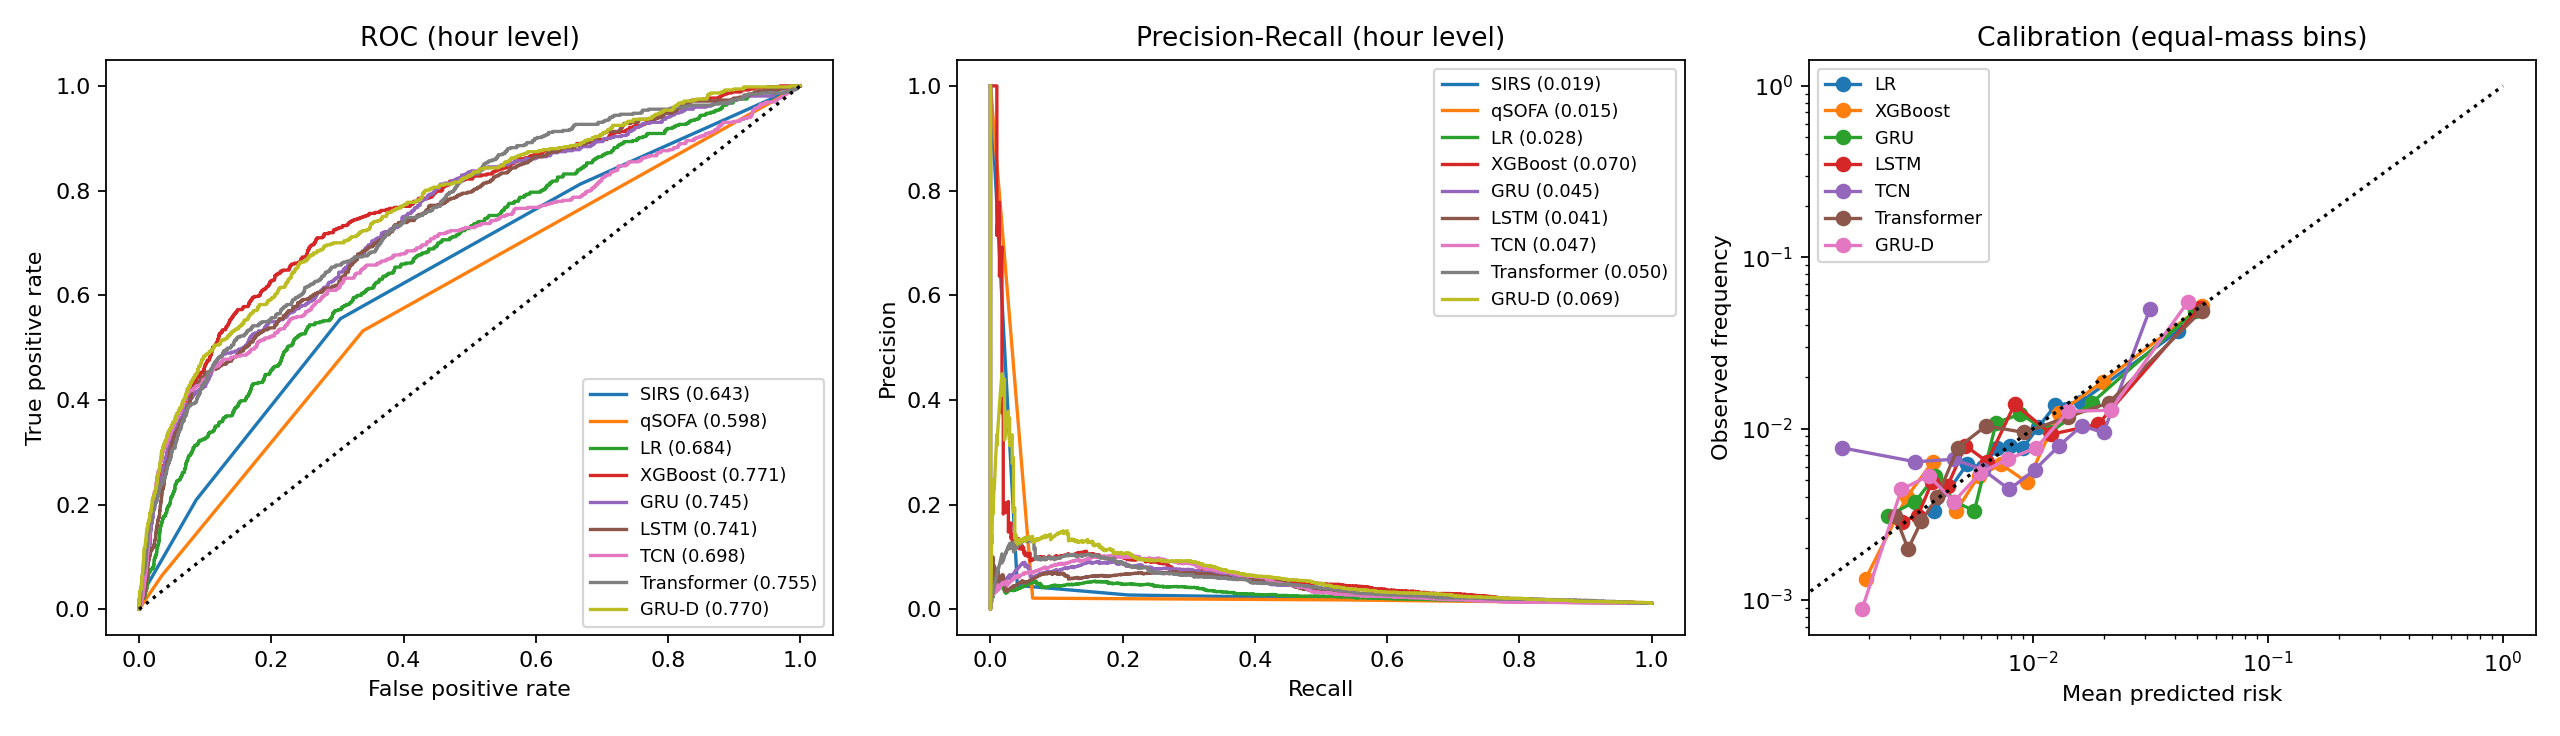

figures/utility.png


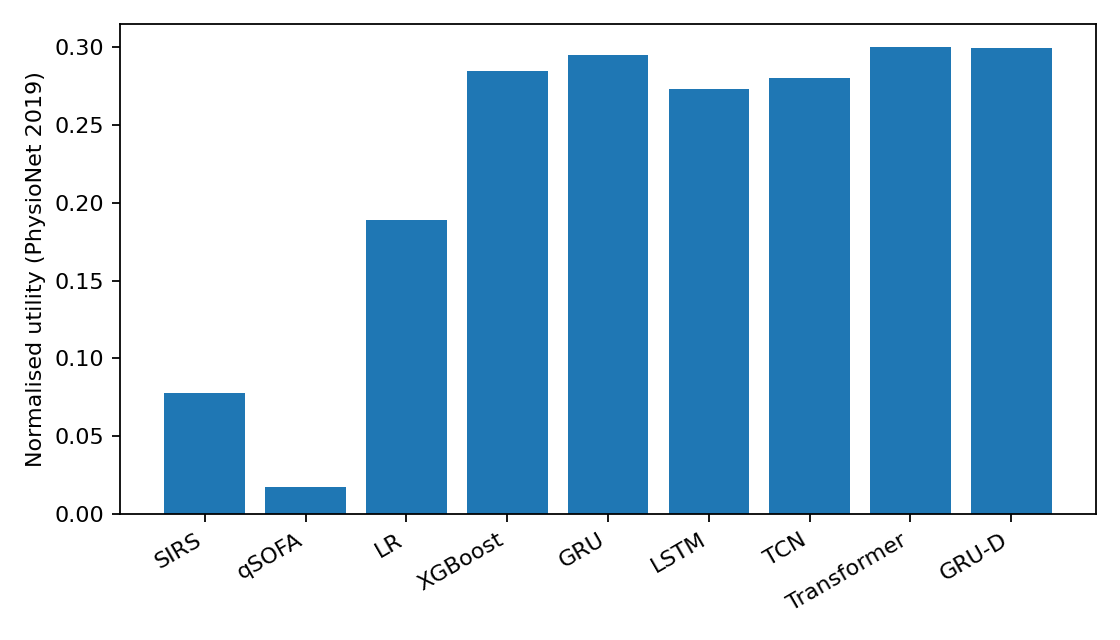

results/gru_w24_h6_random_s0/ig_global.png


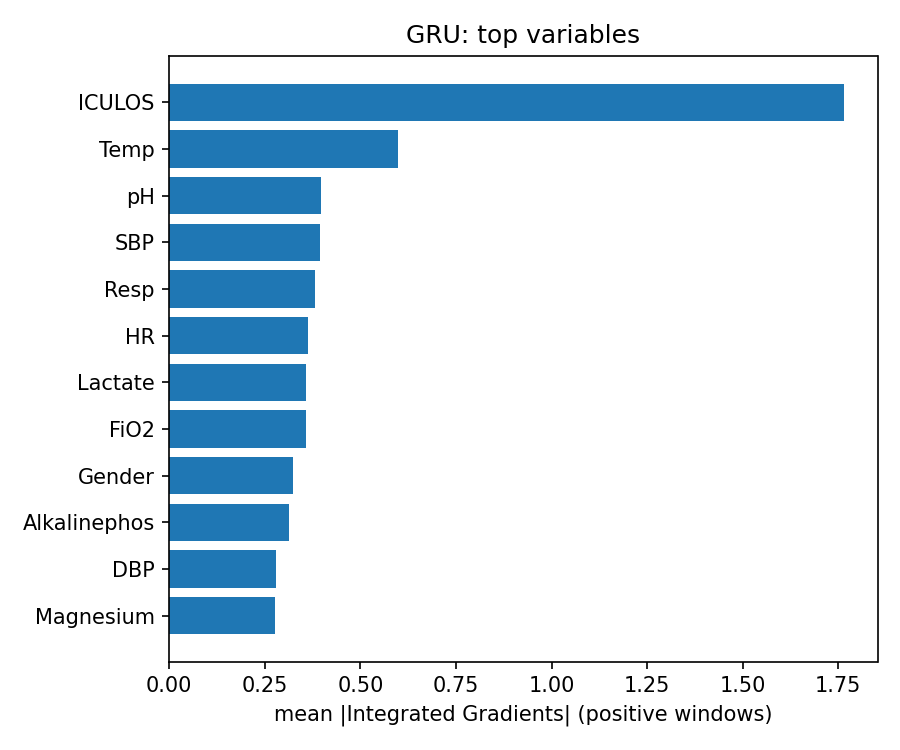

results/gru_w24_h6_random_s0/ig_patient_timeline.png


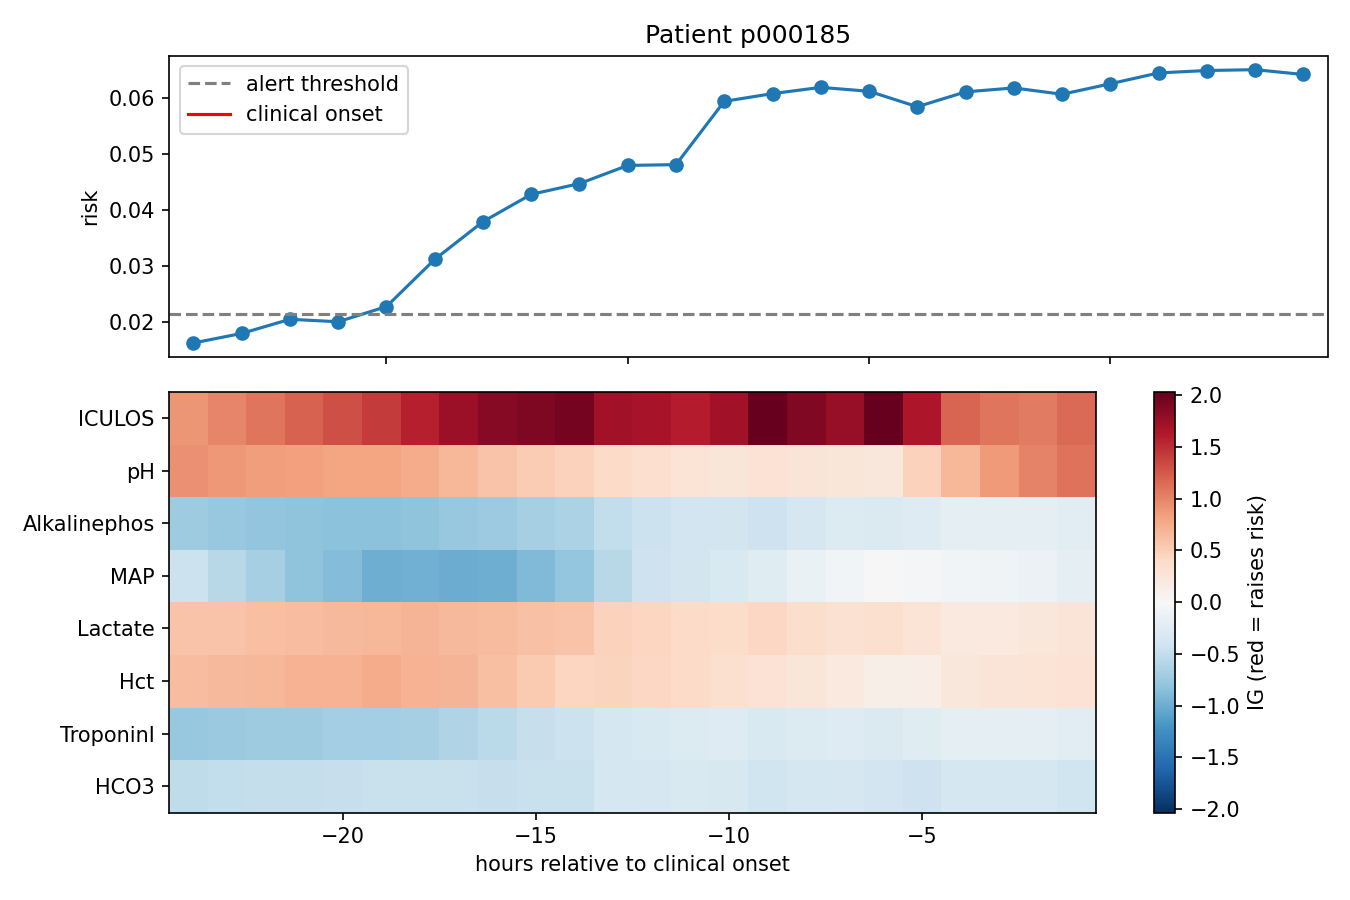

results/gbdt_random_h6_s0/gbdt_importance.png


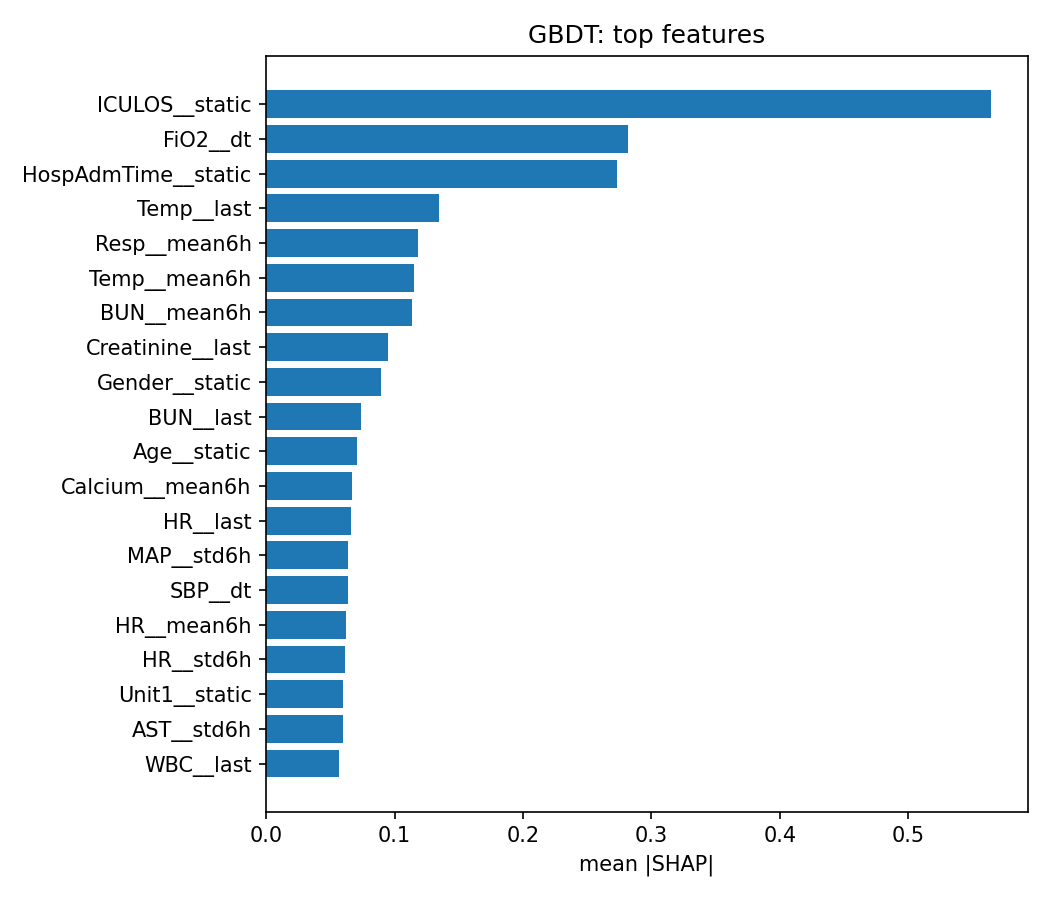

In [20]:
import pandas as pd, glob
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200)
df = pd.read_csv("results/all_runs.csv")
cols = ["AUROC", "AUPRC", "Sens@95spec", "Utility", "Pat.sens", "MedLead(h)", "FalseAlert/100pd"]
order = ["sirs", "qsofa", "lr", "gbdt", "gru", "lstm", "tcn", "transformer", "grud"]
main = df[~df.no_missing]
print("MODEL COMPARISON (test set, mean over seeds; higher is better except FalseAlert)")
display(main.groupby("model")[cols].mean().reindex(order).round(3))
print("STANDARD DEVIATION ACROSS SEEDS")
display(main.groupby("model")[cols].std(ddof=0).reindex(order).round(3))
abl = df[df.model == "gru"].groupby("no_missing")[cols].mean().round(3)
abl.index = ["GRU with missing-data features", "GRU without (ablation)"][:len(abl)] if len(abl) == 2 else abl.index
print("ABLATION")
display(abl)
for p in ["figures/curves.png", "figures/utility.png", "results/gru_w24_h6_random_s0/ig_global.png",
          "results/gru_w24_h6_random_s0/ig_patient_timeline.png", "results/gbdt_random_h6_s0/gbdt_importance.png"]:
    if glob.glob(p):
        print(p); display(Image(p))

## Save everything

In [21]:
!zip -qr sepsis_results.zip results figures
from google.colab import files
files.download("sepsis_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**What the metrics mean (for your report):** AUPRC is the main score (sepsis hours are rare, ~1–2%). *Utility* is the PhysioNet 2019 time-sensitive score
(1 = perfect alert timing, 0 = never alerting). *Pat.sens* = fraction of septic patients alerted before onset; *MedLead(h)* = median hours of warning;
*FalseAlert/100pd* = false-alert hours per 100 patient-days.